# Spider Plot (tumour change from baseline)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

One line per patient tracks the percentage change in tumour size from baseline at each scan. Lines colored by best response show how deep and how durable each response was, and when progression set in. That trajectory is lost in a single best-response waterfall.

## When to use

- Show depth, speed and durability of tumour response in early-phase oncology trials
- Show the timing of progression or discontinuation, patient by patient
- Complement a waterfall plot (best change) and a swimmer plot (time on treatment)

## Avoid when

- There are more than about 40 patients (lines tangle; use a waterfall plus Kaplan–Meier)
- Scans are irregular and sparse (lines suggest continuity that was not measured)
- The audience needs a single summary statistic such as objective response rate

## Alternatives

- Tumour response waterfall
- Swimmer plot
- Small multiples by response category

## Design tips

- Draw the RECIST reference lines (+20% and −30% from baseline) in neutral gray
- RECIST progression is measured from the nadir (+20% and at least 5 mm above the smallest sum so far), not from baseline: a responder can progress while still below the +20% line
- Color by best overall response, not by patient, so the 4 categories stay readable
- Mark why a line ends (progression, toxicity, still on study) with a distinct marker shape

## Example

Simulated phase II cohort of 30 patients scanned every 6 weeks for up to 48 weeks: sum of target-lesion diameters as % change from baseline, colored by best overall response.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(55)
categories = ["Complete response", "Partial response", "Stable disease", "Progressive disease"]
weeks = np.arange(0, 49, 6)
rows = []
for pid in range(1, 31):
    kind = rng.choice(4, p=[0.1, 0.3, 0.3, 0.3])
    depth = [-100, rng.uniform(-75, -35), rng.uniform(-25, 15), rng.uniform(0, 15)][kind]
    speed = rng.uniform(0.15, 0.5)
    regrow = rng.uniform(0.0, 3.5) if kind in (1, 2) and rng.random() < 0.5 else 0.0
    change = []
    for w in weeks:
        y = depth * (1 - np.exp(-speed * w / 6)) + regrow * max(0, w - 18)
        if kind == 3:
            y = depth + rng.uniform(4, 8) * w / 6 * 3
        y = float(np.clip(y + rng.normal(0, 3), -100, 150))
        if kind == 0 and y <= -85:
            y = -100.0                                   # all target lesions have disappeared
        change.append(0.0 if w == 0 else y)
    change = np.array(change)
    # RECIST 1.1 progression: sum of diameters >= 20% above the nadir (smallest sum so far, baseline
    # included) and at least 5 mm larger; with a ~50 mm baseline sum, 5 mm is 10 percentage points.
    size = 100 + change
    nadir = np.minimum.accumulate(size)
    grew = np.r_[False, size[1:] - nadir[:-1] >= np.maximum(0.2 * nadir[:-1], 10)]
    stop = int(np.argmax(grew)) if grew.any() else len(weeks) - 1
    reason = "progression" if grew.any() else "ongoing"
    tox = rng.random() < 0.15
    tox_stop = rng.integers(3, len(weeks) - 1)
    if tox and tox_stop < stop:
        stop, reason = tox_stop, "toxicity"
    seen = change[1:stop + 1]                # scans actually done (baseline excluded)
    best = ("Complete response" if seen.min() <= -100 else "Partial response" if seen.min() <= -30
            else "Progressive disease" if reason == "progression" and stop == 1 else "Stable disease")
    for w, y in zip(weeks[:stop + 1], change[:stop + 1]):
        rows.append((pid, best, w, y, reason))
df = pd.DataFrame(rows, columns=["patient", "best_response", "week", "pct_change", "end_reason"])
df.groupby("best_response")["patient"].nunique()

best_response
Complete response       4
Partial response        7
Progressive disease     9
Stable disease         10
Name: patient, dtype: int64

### Plot

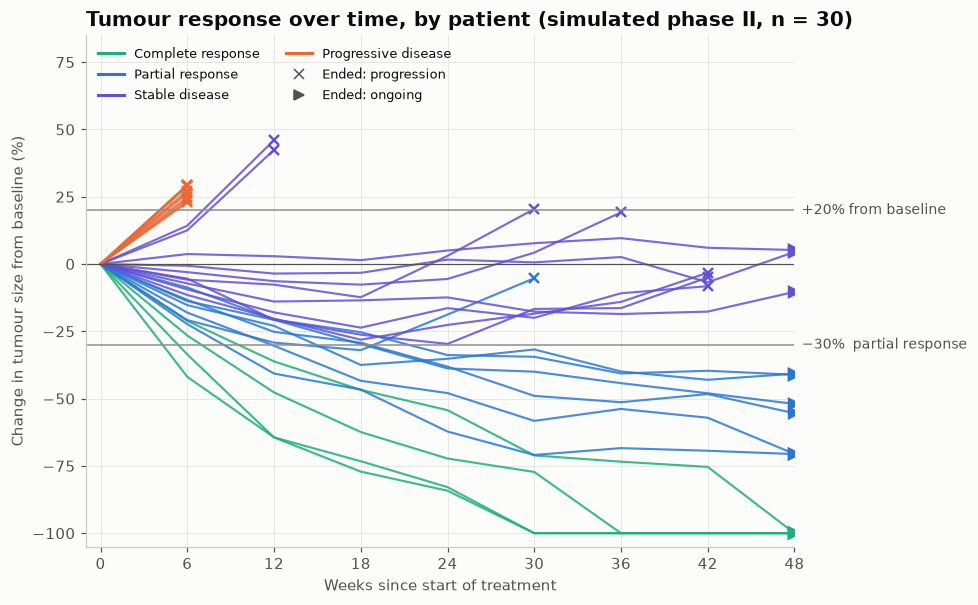

In [3]:
fig, ax = plt.subplots(figsize=(9, 5.6))
markers = {"progression": ("x", 7), "toxicity": ("o", 6), "ongoing": (">", 7)}
for i, cat in enumerate(categories):
    for _, g in df[df["best_response"] == cat].groupby("patient"):
        ax.plot(g["week"], g["pct_change"], color=PALETTE[[2, 0, 6, 1][i]], linewidth=1.4, alpha=0.85)
        m, size = markers[g["end_reason"].iloc[0]]
        ax.plot(g["week"].iloc[-1], g["pct_change"].iloc[-1], m, color=PALETTE[[2, 0, 6, 1][i]],
                markersize=size, markeredgewidth=1.6)
for y, label in [(20, "+20% from baseline"), (-30, "−30%  partial response")]:
    ax.axhline(y, color="#8f8e88", linewidth=1)
    ax.text(48.5, y, label, va="center", ha="left", fontsize=9, color="#52514e")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xticks(weeks)
ax.set_xlim(-1, 48)
ax.set_ylim(-105, 85)
ax.set_xlabel("Weeks since start of treatment")
ax.set_ylabel("Change in tumour size from baseline (%)")
ax.set_title("Tumour response over time, by patient (simulated phase II, n = 30)")
handles = [plt.Line2D([], [], color=PALETTE[[2, 0, 6, 1][i]], label=c) for i, c in enumerate(categories)]
handles += [plt.Line2D([], [], color="#52514e", linestyle="", marker=m, markersize=s, label=f"Ended: {r}")
            for r, (m, s) in markers.items() if r in set(df["end_reason"])]
ax.legend(handles=handles, loc="upper left", fontsize=8.5, ncol=2)
fig.tight_layout()
plt.show()

## How to read it

Lines that dive below the −30% line belong to responders; the green complete responses reach −100% (all target lesions gone). Orange lines progressed at the first scan. A cross marks a line that ended in progression, judged against each patient's nadir: several stable-disease and partial-response lines end with a cross well below the +20% line because they regrew 20% from their lowest point. An arrow marks a patient still on study.

---
Standalone script: [`spider_plot.py`](spider_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)